# Energy performance diagnostics (DPE): principal component analysis

**Nayl Saifoudine** · BUT Science des Données, 2nd year · 2025 · individual project

Built on the [Open Data University](https://www.opendatauniversity.org/) challenge
*Diagnostics de Performance Énergétique*, proposed by Enedis on
[data.gouv.fr](https://www.data.gouv.fr/reuses/defi-diagnostic-de-performance-energetique).

## Context

In France, every dwelling that is sold or rented needs an energy performance diagnostic (DPE).
It rates the dwelling from **A** (most efficient) to **G** on its energy use and greenhouse-gas
emissions; dwellings rated F or G are called *passoires énergétiques* and are being phased out of
the rental market. A DPE record holds well over a hundred numeric fields: consumption per use,
costs, emissions, heat losses through each part of the envelope, solar gains, heating needs…

## Goal

1. Reduce this high-dimensional dataset to a few principal components that keep most of the information.
2. Identify groups of strongly correlated variables.
3. Interpret the main axes to describe the profiles of the dwellings.

## Data

An extract of the ADEME open dataset *DPE Logements existants (depuis juillet 2021)*:
8,718 diagnostics carried out in December 2024 across France. The file in `data/` keeps the
numeric fields and the DPE labels; addresses and identifiers (tax and social-housing numbers,
postcodes, map coordinates) were removed, since they describe *where* a dwelling is, not how it performs.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

DATA = Path("data") / "dpe_existing_dwellings_2024-12.csv.gz"
LABELS = list("ABCDEFG")
LABEL_COLORS = ["#009c6d", "#52b153", "#a5cc74", "#f4e70f", "#f0b40f", "#eb8235", "#d7221f"]

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

## 2. Loading and first look

In [2]:
raw = pd.read_csv(DATA, low_memory=False)
print(f"{raw.shape[0]:,} diagnostics, {raw.shape[1]} columns")
dates = pd.to_datetime(raw["Date_établissement_DPE"])
print(f"Carried out between {dates.min():%d %b %Y} and {dates.max():%d %b %Y}")
raw["Type_bâtiment"].value_counts()

8,718 diagnostics, 150 columns
Carried out between 15 Dec 2024 and 22 Dec 2024


Type_bâtiment
appartement    5792
maison         2666
immeuble        260
Name: count, dtype: int64

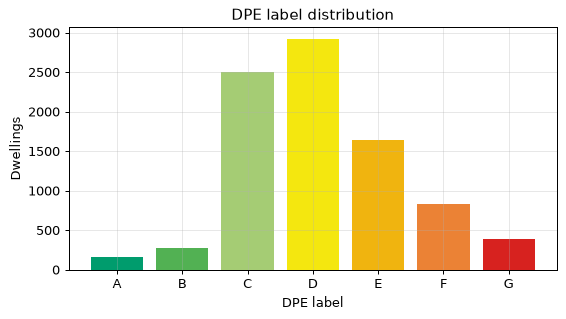

Dwellings rated F or G: 13.9%


In [3]:
counts = raw["Etiquette_DPE"].value_counts().reindex(LABELS, fill_value=0)
share_fg = counts[["F", "G"]].sum() / counts.sum()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(counts.index, counts.values, color=LABEL_COLORS)
ax.set(title="DPE label distribution", xlabel="DPE label", ylabel="Dwellings")
plt.show()
print(f"Dwellings rated F or G: {share_fg:.1%}")

## 3. Preparing the variables

PCA works on numeric variables only. Three cleaning steps:

- keep the numeric columns;
- drop the columns that are empty for half of the dwellings or more (mostly second heating or
  hot-water systems, which few dwellings have);
- drop the constant columns, which carry no information;

then fill the remaining gaps with the column mean and **standardise** every variable (mean 0,
variance 1), so that kWh, euros and m² weigh the same in the analysis.

In [4]:
numeric = raw.select_dtypes(include=np.number)
print("Numeric columns:", numeric.shape[1])

X = numeric.loc[:, numeric.isna().mean() < 0.5]
print("After dropping columns at least 50% empty:", X.shape[1])

X = X.loc[:, X.nunique() > 1]
print("After dropping constant columns:", X.shape[1])

X = X.fillna(X.mean())
Z = StandardScaler().fit_transform(X)
print(f"Matrix analysed: {Z.shape[0]:,} dwellings x {Z.shape[1]} variables")

Numeric columns: 146
After dropping columns at least 50% empty: 96
After dropping constant columns: 95
Matrix analysed: 8,718 dwellings x 95 variables


## 4. Correlations between variables

Large red blocks show families of variables that move together: consumptions, costs and
emissions of the same use, or the different heat-loss terms. This redundancy is what makes a
PCA worthwhile.

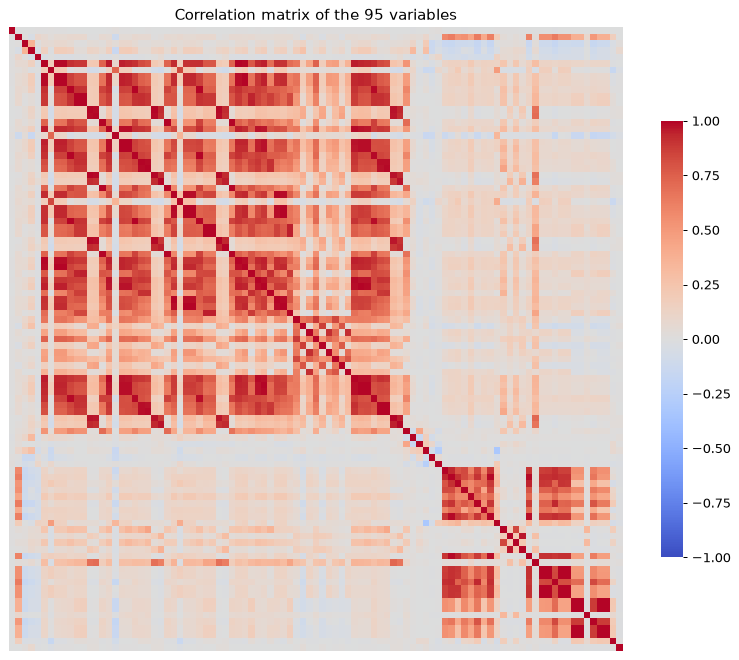

In [5]:
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title(f"Correlation matrix of the {X.shape[1]} variables")
plt.show()

## 5. Principal component analysis

In [6]:
pca = PCA().fit(Z)
scores = pca.transform(Z)
ratio = pca.explained_variance_ratio_
cumulative = np.cumsum(ratio)

n80 = int(np.argmax(cumulative >= 0.80)) + 1
n90 = int(np.argmax(cumulative >= 0.90)) + 1
print(f"PC1 {ratio[0]:.1%}, PC2 {ratio[1]:.1%}: first plane {cumulative[1]:.1%}")
print(f"{n80} components keep 80% of the variance, {n90} keep 90% (out of {Z.shape[1]} variables)")

pd.DataFrame({
    "Eigenvalue": pca.explained_variance_[:10],
    "% variance": ratio[:10] * 100,
    "Cumulative %": cumulative[:10] * 100,
}, index=[f"PC{i}" for i in range(1, 11)]).round(2)

PC1 34.5%, PC2 14.7%: first plane 49.2%
11 components keep 80% of the variance, 20 keep 90% (out of 95 variables)


,Eigenvalue,% variance,Cumulative %
PC1,32.80,34.52,34.52
PC2,13.92,14.66,49.18
PC3,8.33,8.76,57.94
PC4,5.01,5.27,63.22
PC5,3.37,3.55,66.77
PC6,2.84,2.99,69.76
PC7,2.55,2.68,72.44
PC8,2.31,2.43,74.88
PC9,2.09,2.20,77.08
PC10,1.75,1.84,78.92


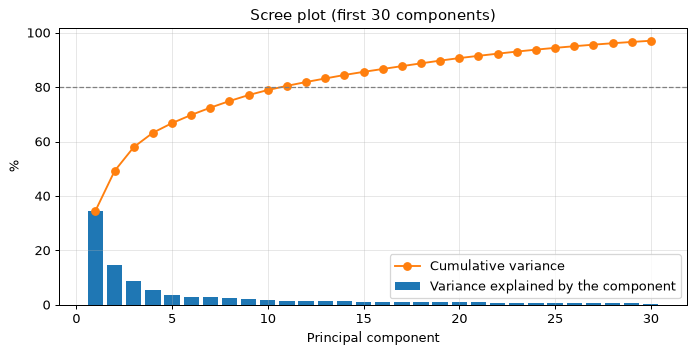

In [7]:
k = 30
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, k + 1), ratio[:k] * 100, label="Variance explained by the component")
ax.plot(range(1, k + 1), cumulative[:k] * 100, marker="o", color="C1", label="Cumulative variance")
ax.axhline(80, color="grey", linestyle="--", linewidth=1)
ax.set(title=f"Scree plot (first {k} components)", xlabel="Principal component", ylabel="%")
ax.legend()
plt.show()

**Check by hand.** The principal components are the eigenvectors of the correlation matrix,
and their variances are its eigenvalues. Diagonalising that matrix with NumPy gives the same
shares of variance as scikit-learn.

In [8]:
eigenvalues, eigenvectors = np.linalg.eigh(np.corrcoef(Z, rowvar=False))
eigenvalues = eigenvalues[::-1]
print("Same shares of variance as scikit-learn:",
      np.allclose(eigenvalues / eigenvalues.sum(), ratio))

Same shares of variance as scikit-learn: True


## 6. What the first two axes mean

The **loading** of a variable on a component is its correlation with that component.

In [9]:
loadings = pd.DataFrame(pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2]),
                        index=X.columns, columns=["PC1", "PC2"])
top_pc1 = loadings["PC1"].sort_values(key=abs, ascending=False).head(10)
top_pc2 = loadings["PC2"].sort_values(key=abs, ascending=False).head(10)
pd.concat([top_pc1.rename("loading").to_frame().assign(component="PC1"),
           top_pc2.rename("loading").to_frame().assign(component="PC2")]).round(2)

,loading,component
Coût_total_5_usages,0.97,PC1
Conso_5_usages_é_finale,0.97,PC1
Conso_5_usages_é_finale_énergie_n°1,0.97,PC1
Conso_5_usages_é_primaire,0.96,PC1
Coût_total_5_usages_énergie_n°1,0.95,PC1
Coût_chauffage,0.94,PC1
Conso_chauffage_dépensier_é_finale,0.94,PC1
Coût_chauffage_énergie_n°1,0.94,PC1
Conso_chauffage_é_finale,0.94,PC1
Coût_chauffage_dépensier,0.94,PC1


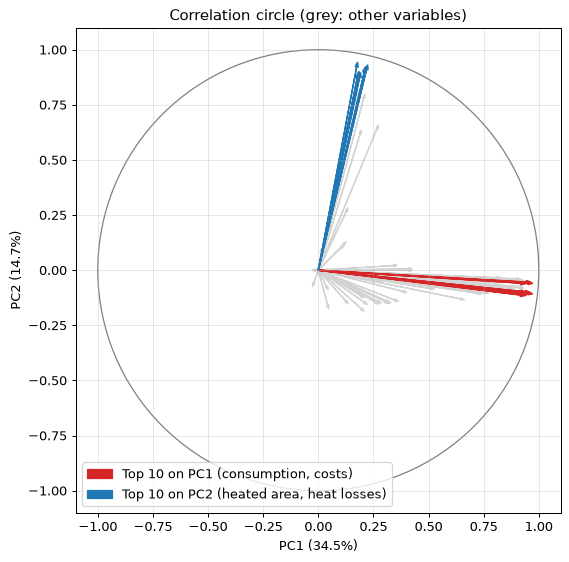

In [10]:
groups = {"Top 10 on PC1 (consumption, costs)": (top_pc1.index, "C3"),
          "Top 10 on PC2 (heated area, heat losses)": (top_pc2.index, "C0")}

fig, ax = plt.subplots(figsize=(7, 7))
for name, (x, y) in loadings.iterrows():
    ax.arrow(0, 0, x, y, color="lightgrey", head_width=0.012, length_includes_head=True)
for label, (names, color) in groups.items():
    for i, name in enumerate(names):
        x, y = loadings.loc[name]
        ax.arrow(0, 0, x, y, color=color, head_width=0.015, length_includes_head=True,
                 label=label if i == 0 else None)
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), aspect="equal",
       xlabel=f"PC1 ({ratio[0]:.1%})", ylabel=f"PC2 ({ratio[1]:.1%})",
       title="Correlation circle (grey: other variables)")
ax.legend(loc="lower left")
plt.show()

- **PC1: total energy use and cost.** Total and heating consumption (final and primary energy)
  and their costs are almost perfectly correlated with it. These are *totals*, not values per m².
- **PC2: size of the heating installation and its heat losses.** Heated area of the main
  installation, envelope losses, air renewal, glazing and thermal bridges, and the heating need.

Both axes are about **volume**. The variables per m² (consumption, emissions) barely load on
either of them.

## 7. Who sits where on the first plane

The dataset mixes diagnostics of single dwellings (houses, flats) with diagnostics of **whole
buildings** (*immeuble*). Since PC1 measures totals, the type of diagnostic should matter.

In [11]:
by_type = pd.DataFrame({"PC1": scores[:, 0], "PC2": scores[:, 1], "type": raw["Type_bâtiment"]})
by_type.groupby("type")[["PC1", "PC2"]].agg(["mean", "median"]).round(2)

PC1          PC2       
              mean median  mean median
type                                  
appartement  -0.85  -1.14  0.73  -1.31
immeuble     19.55  10.76 -1.88  -1.54
maison       -0.07  -0.41 -1.41  -1.39

Whole-building diagnostics, only 3% of the rows, sit far out on PC1: a building uses far more
energy in total than one flat. On PC2, most flats sit low, but the mean is pulled up by
flats served by a collective heating system, whose installation figures describe the whole
building.

The DPE label was **not** used to build the components. Colouring the dwellings by their label
checks whether the first axis matches the official rating.

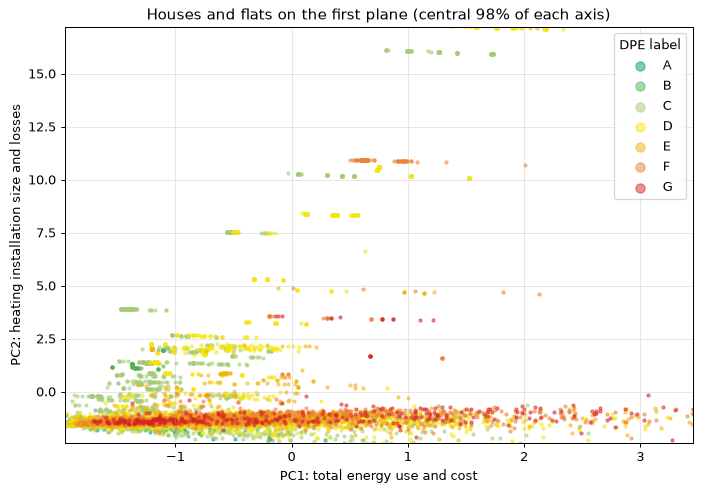

Spearman correlation between PC1 and the DPE label: 0.34


,PC1,PC2
label,,
A,-1.33,-1.58
B,-0.70,-0.93
C,-0.54,0.13
D,0.11,0.77
E,0.13,-1.05
F,1.08,0.10
G,0.77,-1.07


In [12]:
plane = pd.DataFrame({"PC1": scores[:, 0], "PC2": scores[:, 1], "label": raw["Etiquette_DPE"]})
plane = plane[plane["label"].isin(LABELS)]

dwellings = plane[raw.loc[plane.index, "Type_bâtiment"] != "immeuble"]
low, high = dwellings[["PC1", "PC2"]].quantile(0.01), dwellings[["PC1", "PC2"]].quantile(0.99)

fig, ax = plt.subplots(figsize=(9, 6))
for label, color in zip(LABELS, LABEL_COLORS):
    part = dwellings[dwellings["label"] == label]
    ax.scatter(part["PC1"], part["PC2"], s=6, alpha=0.5, color=color, label=label)
ax.set(xlim=(low["PC1"], high["PC1"]), ylim=(low["PC2"], high["PC2"]),
       xlabel="PC1: total energy use and cost", ylabel="PC2: heating installation size and losses",
       title="Houses and flats on the first plane (central 98% of each axis)")
ax.legend(title="DPE label", markerscale=3)
plt.show()

means = plane.groupby("label")[["PC1", "PC2"]].mean().reindex(LABELS)
rank_corr = plane["PC1"].corr(plane["label"].map({l: i for i, l in enumerate(LABELS)}),
                              method="spearman")
print(f"Spearman correlation between PC1 and the DPE label: {rank_corr:.2f}")
means.round(2)

In [13]:
label_rank = raw["Etiquette_DPE"].map({l: i for i, l in enumerate(LABELS)})
for column in ["Conso_5_usages_par_m²_é_primaire", "Conso_5_usages/m²_é_finale", "Conso_5_usages_é_finale"]:
    print(f"Spearman correlation with the DPE label, {column}: {X[column].corr(label_rank, method='spearman'):.2f}")

Spearman correlation with the DPE label, Conso_5_usages_par_m²_é_primaire: 0.94
Spearman correlation with the DPE label, Conso_5_usages/m²_é_finale: 0.75
Spearman correlation with the DPE label, Conso_5_usages_é_finale: 0.46


The label rises with PC1 on average (A dwellings sit on the left, F and G on the right), but
the link is moderate. The DPE label is computed from **primary energy per m²**, which
correlates almost perfectly with it, while PC1 measures totals. A small, badly insulated flat
and a large, efficient house can use the same amount of energy in total.

## 8. Quality of representation

The squared cosine (cos²) of a dwelling measures how much of its position is captured by the
first plane. Above 0.5, the dwelling is considered well represented.

In [14]:
cos2 = (scores[:, :2] ** 2).sum(axis=1) / (scores ** 2).sum(axis=1)
print(f"Dwellings well represented on PC1-PC2 (cos² >= 0.5): {(cos2 >= 0.5).mean():.1%}")

Dwellings well represented on PC1-PC2 (cos² >= 0.5): 9.3%


With all the variables, the first plane represents few dwellings well: much of their
variance is spread over minor components. The next step keeps only the variables that
build the first plane.

## 9. PCA on the most informative variables

Keep the variables whose weight in the first two eigenvectors is at least 0.1
(norm of their (PC1, PC2) coordinates in `pca.components_`), then run the PCA again.

In [15]:
weights = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])
selected = weights.index[np.hypot(weights["PC1"], weights["PC2"]) >= 0.1]
print(f"Variables kept: {len(selected)} of {X.shape[1]}")

Z_sel = StandardScaler().fit_transform(X[selected])
pca_sel = PCA().fit(Z_sel)
scores_sel = pca_sel.transform(Z_sel)
ratio_sel = pca_sel.explained_variance_ratio_
cumulative_sel = np.cumsum(ratio_sel)

cos2_sel = (scores_sel[:, :2] ** 2).sum(axis=1) / (scores_sel ** 2).sum(axis=1)
print(f"First plane: {cumulative_sel[1]:.1%} of the variance")
print(f"{int(np.argmax(cumulative_sel >= 0.80)) + 1} components keep 80% of the variance")
print(f"Dwellings well represented on PC1-PC2 (cos² >= 0.5): {(cos2_sel >= 0.5).mean():.1%}")

Variables kept: 58 of 95
First plane: 76.4% of the variance
3 components keep 80% of the variance
Dwellings well represented on PC1-PC2 (cos² >= 0.5): 79.8%


## 10. Conclusion

- **The DPE records are highly redundant.** 11 components keep 80% of the information carried
  by 95 variables, and the first two keep 49%.
- **Two dimensions dominate, both about volume:** total energy use and cost (PC1, 34.5%), and
  the size and heat losses of the heating installation (PC2, 14.7%).
- **The main axes are not the DPE label.** The label is a per-m² measure (Spearman 0.94 with
  primary energy per m²) and is only moderately linked to PC1 (0.34).
- **A reduced set of 58 variables** brings the first plane to 76% of the variance, with 80% of
  the dwellings well represented (cos² ≥ 0.5, against 9% with all the variables).

**Limits and next steps.**
- Whole-building diagnostics (3% of the rows) dominate PC1. A next version should analyse them
  separately from single dwellings.
- Several variables are near-duplicates (final and primary energy, "dépensier" variants), which
  inflates the weight of consumption.
- Working on per-m² variables would focus the analysis on efficiency rather than size.
- Gaps were filled with the column mean, and the extract covers one week of diagnostics, not a
  representative sample of the French housing stock.